In [1]:
import kagglehub, shutil, os
import pandas as pd

path = kagglehub.dataset_download("prasad22/healthcare-dataset")
os.makedirs("data", exist_ok=True)
shutil.copy(os.path.join(path, "healthcare_dataset.csv"), "data/healthcare_dataset.csv")

df = pd.read_csv("data/healthcare_dataset.csv")
df.head()

c:\Users\Maxwell\Documents\Data Analytics\Healthcare-Dataset\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [2]:
#structure and data qualities
print(df.shape)
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

#numbers and categories
display(df.describe())
for col in ["Gender", "Medical Condition", "Admission Type", "Test Results"]:
    print(df[col].value_counts(normalize=True).round(3), "\n")

(55500, 15)
<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 6.4 M

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


Gender
Male      0.5
Female    0.5
Name: proportion, dtype: float64 

Medical Condition
Arthritis       0.168
Diabetes        0.168
Hypertension    0.167
Obesity         0.166
Cancer          0.166
Asthma          0.165
Name: proportion, dtype: float64 

Admission Type
Elective     0.336
Urgent       0.335
Emergency    0.329
Name: proportion, dtype: float64 

Test Results
Abnormal        0.336
Normal          0.334
Inconclusive    0.331
Name: proportion, dtype: float64 



In [3]:
df.nunique().sort_values()
print(df["Name"].sample(10, random_state=1))
print("\nNegative billing amounts:", (df["Billing Amount"] < 0).sum())
print("Smallest bill:", df["Billing Amount"].min())

32354        MichAel MILLs
46537      wiLlIam RAmirEz
34234         JosEph MeYER
54136    DR. micHaEl MckAy
16406     MoNiCA CaRpEnTER
45858          ERIC HuRLey
11578      daNieLle hAYNES
50172         NICole HeNrY
36796          raCHAel LeE
487             ANn dUNCAN
Name: Name, dtype: str

Negative billing amounts: 108
Smallest bill: -2008.4921398591305


In [4]:
adm = pd.to_datetime(df["Date of Admission"])
dis = pd.to_datetime(df["Discharge Date"])

print("Admissions range:", adm.min().date(), "to", adm.max().date())
print("Discharged before admitted:", (dis < adm).sum())
print((dis - adm).dt.days.describe())

Admissions range: 2019-05-08 to 2024-05-07
Discharged before admitted: 0
count    55500.000000
mean        15.509009
std          8.659600
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
dtype: float64


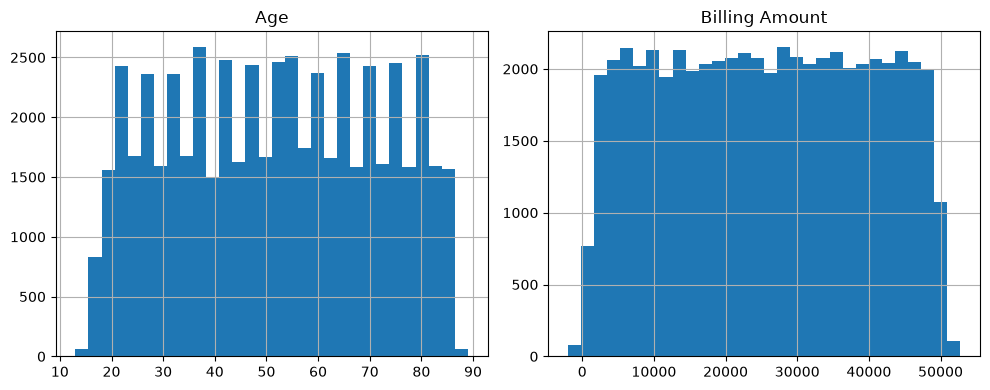

In [5]:
import matplotlib.pyplot as plt

df[["Age", "Billing Amount"]].hist(bins=30, figsize=(10, 4))
plt.tight_layout()
plt.show()

Observations 
-55,000 rows and 15 columns, fortunately there isn't any missing values (most likely due to synthetic data)
-543 duplicate rows, drop the duplicate rows (later found age duplication problem)
-change date of admssion to datetime instead of text
-fix capitalization of the names, random capital letters
-check for suffixes and remove them
-108 negative billing amounts, figure out what to do with them
-billing needs to be rounded to 2 decimal places
